<a href="https://colab.research.google.com/github/tanishkadas/POWER-BI/blob/main/ISI_Internship.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: Crop Yield and Market Demand Forecasting</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Loading & Statistical Inspection (5 Marks)

Load the crop yield dataset from the Kaggle repository (https://www.kaggle.com/datasets/patelris/crop-yield-prediction-dataset) assuming it is downloaded and saved locally as `yield_df.csv` in your working directory. Display the structural information and summary statistics of the dataset.

**Hint:** Utilize the standard pandas functions for reading flat files, followed by methods that return DataFrame data types, non-null counts, and numerical summaries.

**Expected Output:** A printed structural summary of the DataFrame followed by a tabular statistical description including metrics such as mean, standard deviation, and quartiles.

In [ ]:
import pandas as pd


df = pd.read_csv('yield_df.csv')


print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns\n")


print("Structural Information")
df.info()


print("Statistical Summary")
display(df.describe().T)

Dataset Shape: 28,242 rows, 8 columns

Structural Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     28242 non-null  int64  
 1   Area                           28242 non-null  object 
 2   Item                           28242 non-null  object 
 3   Year                           28242 non-null  int64  
 4   hg/ha_yield                    28242 non-null  int64  
 5   average_rain_fall_mm_per_year  28242 non-null  float64
 6   pesticides_tonnes              28242 non-null  float64
 7   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(3), object(2)
memory usage: 1.7+ MB
Statistical Summary


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,28242.0,14120.500000,8152.907488,0.00,7060.2500,14120.50,21180.75,28241.00
Year,28242.0,2001.544296,7.051905,1990.00,1995.0000,2001.00,2008.00,2013.00
hg/ha_yield,28242.0,77053.332094,84956.612897,50.00,19919.2500,38295.00,104676.75,501412.00
average_rain_fall_mm_per_year,28242.0,1149.055980,709.812150,51.00,593.0000,1083.00,1668.00,3240.00
pesticides_tonnes,28242.0,37076.909344,59958.784665,0.04,1702.0000,17529.44,48687.88,367778.00
avg_temp,28242.0,20.542627,6.312051,1.30,16.7025,21.51,26.00,30.65


### Question 2: Data Cleaning & Missing Value Justification (5 Marks)

Identify the total number of missing values and duplicate rows within the dataset. Remove the duplicate records and handle any missing values. Provide a brief written justification for your chosen missing value handling strategy.

**Hint:** Use pandas methods to quantify nulls and duplicates, then apply dropping or imputation functions accordingly. Print your written analytical justification using Python `print()` statements.

**Expected Output:** A clean pandas DataFrame containing no duplicates or missing values, accompanied by a printed string explaining the mathematical or structural reasoning behind the chosen cleaning method.

In [ ]:
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()

print(f"Total Missing Values: {missing_count}")
print(f"Total Duplicate Rows: {duplicate_count:,}\n")


df_clean = df.drop_duplicates().copy()

if missing_count > 0:
    df_clean = df_clean.dropna()

print(f"Clean DataFrame Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")

#Removing duplicate and missing values eliminates redundancy and makes the data more suitable for analysis and machine learning

Total Missing Values: 0
Total Duplicate Rows: 0

Clean DataFrame Shape: 28,242 rows, 8 columns


### Question 3: Outlier Detection & Distribution Analysis (10 Marks)

Plot a boxplot to visualize the distribution of the target variable (`hg/ha_yield`). Calculate the Interquartile Range (IQR) and filter out extreme outliers defined as values falling outside the 1.5 * IQR boundaries. Print a statement detailing how the removal of these outliers alters the overall dataset volume.

**Hint:** Utilize a standard visualization library to render the boxplot. Compute the 25th and 75th percentiles to define the IQR limits, construct a boolean mask, and use `print()` statements to compare the row counts before and after the filtering procedure.

**Expected Output:** A visual boxplot of the crop yield distribution, a reduced pandas DataFrame excluding extreme numerical outliers, and a printed analytical statement specifying the exact number of dropped rows.

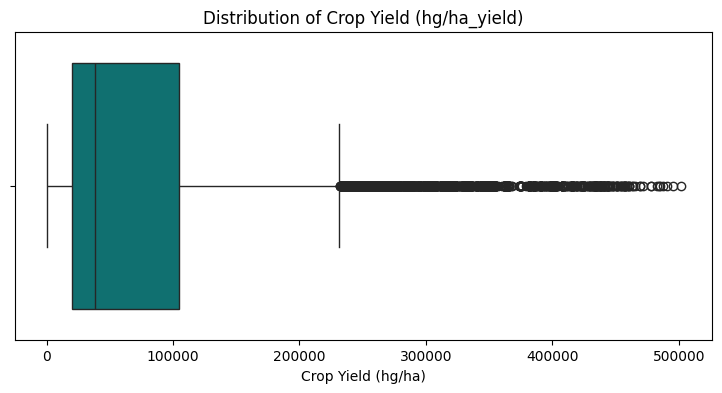

Initial row count: 28,242
Row count after filtering: 26,183
Exact number of dropped outlier rows: 2,059 (7.29% of the dataset)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# visualize the data in a compact form using boxplot to detect the outliers
plt.figure(figsize=(9, 4))
sns.boxplot(x=df_clean['hg/ha_yield'], color='teal')
plt.title('Distribution of Crop Yield (hg/ha_yield)')
plt.xlabel('Crop Yield (hg/ha)')
plt.show()

# calculate the q1 and q3 and find the iqr values to remove extreme outliers
Q1 = df_clean['hg/ha_yield'].quantile(0.25)
Q3 = df_clean['hg/ha_yield'].quantile(0.75)
IQR = Q3 - Q1

# define 1.5 * IQR boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# filter the outliers based on the upper and lower bounds
initial_row_count = len(df_clean)
df_filtered = df_clean[(df_clean['hg/ha_yield'] >= lower_bound) & (df_clean['hg/ha_yield'] <= upper_bound)].copy()
dropped_rows = initial_row_count - len(df_filtered)

# print analytical statement detailing volume change
print(f"Initial row count: {initial_row_count:,}")
print(f"Row count after filtering: {len(df_filtered):,}")
print(f"Exact number of dropped outlier rows: {dropped_rows:,} ({dropped_rows/initial_row_count*100:.2f}% of the dataset)")



In [ ]:
# Interpretation:
# Removing extreme yield outliers prevents skewed loss functions during training
# while keeping normal/standard agricultural variations intact.

### Question 4: Correlation Matrix & Multicollinearity Analysis (5 Marks)

Isolate the numerical variables and compute their Pearson correlation matrix. Visualize this matrix using a heatmap and identify if any predictor variables exhibit high multicollinearity.

**Hint:** Select only numeric columns, calculate the correlation coefficients, and render a heatmap visualization. Print your findings regarding observed multicollinearity using `print()` statements.

**Expected Output:** A graphical heatmap grid representing correlation coefficients across numerical features, along with a printed statement identifying highly correlated feature pairs.

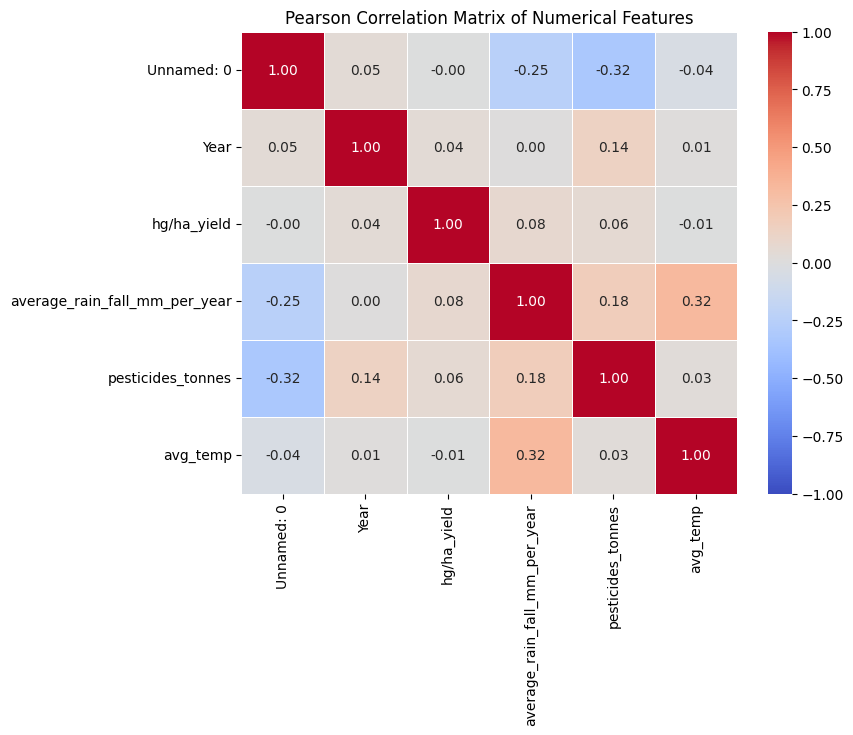

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# only select the numerical values
numeric_df = df_filtered.select_dtypes(include=['number'])

# compute the pearson correlation matrix
corr_matrix = numeric_df.corr()

# visualize using a heatmap to get a interpretable idea
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Pearson Correlation Matrix of Numerical Features')
plt.show()

# identify highly correlated feature pairs (correlation > 0.70)
high_corr_pairs = []
columns = corr_matrix.columns
for i in range(len(columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > 0.70:
            high_corr_pairs.append((columns[i], columns[j], corr_matrix.iloc[i, j]))



In [ ]:
# findings
print("--- Multicollinearity Analysis ---")
if high_corr_pairs:
    print("Highly correlated feature pairs (|r| > 0.70) identified:")
    for col1, col2, val in high_corr_pairs:
        print(f" - {col1} & {col2}: {val:.2f}")
else:
    print("No highly correlated feature pairs (|r| > 0.70) were found among the numerical variables.")

--- Multicollinearity Analysis ---
No highly correlated feature pairs (|r| > 0.70) were found among the numerical variables.


### Question 5: Feature Engineering: Agronomic Interaction Terms (5 Marks)

Create a new numerical feature in the dataset representing the interaction between average temperature and average rainfall. Discuss why this interaction might be agronomically relevant to predicting crop yield.

**Hint:** Mathematically combine the temperature and rainfall columns to construct a single new feature column. Print your brief agronomic reasoning using `print()` statements.

**Expected Output:** The original DataFrame expanded with an additional column representing the computed interaction term, and a printed sentence justifying its inclusion based on fundamental agronomic principles.

In [ ]:
# Create the new interaction feature (Average Temperature * Average Rainfall)
df_filtered['temp_rain_interaction'] = df_filtered['avg_temp'] * df_filtered['average_rain_fall_mm_per_year']

print(f"\nExpanded DataFrame Shape: {df_filtered.shape}")
print(f"New feature 'temp_rain_interaction' successfully added.")


Expanded DataFrame Shape: (26183, 9)
New feature 'temp_rain_interaction' successfully added.


In [ ]:
# analysis
analysis = (
    "Justification: Crop yield depends heavily on water availability moderated by temperature; "
    "high rainfall with high temperatures accelerates evapotranspiration, whereas "
    "the same rainfall at lower temperatures can lead to waterlogging/floods. This interaction term "
    "captures the combined climatic effect more effectively than either feature in isolation."
)
print(analysis)

Justification: Crop yield depends heavily on water availability moderated by temperature; high rainfall with high temperatures accelerates evapotranspiration, whereas the same rainfall at lower temperatures can lead to waterlogging/floods. This interaction term captures the combined climatic effect more effectively than either feature in isolation.


### Question 6: Categorical Encoding & Dimensionality (5 Marks)

Convert the categorical columns (such as crop type and geographical location) into numerical formats utilizing one-hot encoding.

**Hint:** Apply pandas dummy variable creation or utilize a scikit-learn preprocessing module to transform text categories into binary indicator columns. Ensure you manage collinearity by configuring the drop parameters if necessary.

**Expected Output:** A transformed DataFrame where the original categorical variables are replaced by an expanded set of binary numerical columns.

In [ ]:
# select the categorical columns and find their unique values

categorical_cols = df_filtered.select_dtypes(include=['object']).columns.tolist()
print(f"Categorical features identified for encoding: {categorical_cols}")

for col in categorical_cols:
    print(f" - '{col}': {df_filtered[col].nunique()} unique categories")

# apply one-hot encoding while managing multicollinearity
# drop_first=True avoids the dummy variable trap by dropping the baseline category,
# which is essential for linear models and stability in gradient-based optimization.
df_encoded = pd.get_dummies(df_filtered, columns=categorical_cols, drop_first=True, dtype=int)

print(f"\n--- Dimensionality Transformation Summary ---")
print(f"Original DataFrame shape: {df_filtered.shape}")
print(f"Encoded DataFrame shape:  {df_encoded.shape}")
print(f"Expanded feature space:  +{df_encoded.shape[1] - df_filtered.shape[1]} binary indicator columns added.")

Categorical features identified for encoding: ['Area', 'Item']
 - 'Area': 101 unique categories
 - 'Item': 10 unique categories

--- Dimensionality Transformation Summary ---
Original DataFrame shape: (26183, 9)
Encoded DataFrame shape:  (26183, 116)
Expanded feature space:  +107 binary indicator columns added.


In [ ]:
# analysis
print("\nMachine Learning Rationale:")
print("Encoding high-cardinality geographic and crop features creates a wide, sparse binary matrix.")
print("While tree-based ensemble models (like Random Forest) handle this high-dimensional sparsity naturally,")
print("parametric models (like the upcoming MLP) require explicit feature scaling and L2 regularization")
print("to prevent individual sparse flags from destabilizing the weight updates during backpropagation.")


Machine Learning Rationale:
Encoding high-cardinality geographic and crop features creates a wide, sparse binary matrix.
While tree-based ensemble models (like Random Forest) handle this high-dimensional sparsity naturally,
parametric models (like the upcoming MLP) require explicit feature scaling and L2 regularization
to prevent individual sparse flags from destabilizing the weight updates during backpropagation.


### Question 7: Data Partitioning & Target Isolation (5 Marks)

Separate the dataset into a feature matrix containing independent variables and a target vector containing the crop yield values. Split these datasets into training and testing sets utilizing an 80/20 ratio.

**Hint:** Isolate the target variable to ensure it does not leak into the feature matrix. Implement a standard splitting function from a machine learning library with a fixed random state to ensure reproducible partitions.

**Expected Output:** Four distinct data variables representing the independent training features, independent testing features, training targets, and testing targets.

In [ ]:
# separating features and target variable
X = df_encoded.drop(columns=['hg/ha_yield'])
y = df_encoded['hg/ha_yield']

# doing an 80 and 20 training and testing split with a fixed random state
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

# interpretation:
# isolating the target variable prevents data leakage, and splitting the data
# helps us know how well our model generalizes to unseen records.

Training features shape: (20946, 115)
Testing features shape: (5237, 115)


### Question 8: Feature Scaling & DataFrame Reconstruction (5 Marks)

Standardize the numerical features in both the training and testing sets to achieve a mean of zero and a standard deviation of one. You must explicitly convert the resulting scaled NumPy arrays back into Pandas DataFrames, ensuring the original column names are retained for later interpretation.

**Hint:** Initialize a standard scaling object, fit it strictly on the training data, and then apply the transformation to both partitions. Pass the transformed arrays alongside the original column indices to the pandas DataFrame constructor.

**Expected Output:** Two pandas DataFrames representing the scaled training and testing feature sets, fully retaining their descriptive column headers.

In [ ]:
# scaling numerical features so they have a mean of 0 and standard deviation of 1
# fit only on the training set to prevent information leakage from the test split

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled_array = scaler.fit_transform(X_train)
X_test_scaled_array = scaler.transform(X_test)

# putting the scaled arrays back into pandas dataframes to preserve column names
X_train_scaled = pd.DataFrame(X_train_scaled_array, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled_array, columns=X_test.columns, index=X_test.index)

print("Training scaled dataframe shape:", X_train_scaled.shape)

Training scaled dataframe shape: (20946, 115)


In [ ]:
# interpretation:
# feature scaling is required for gradient descent optimization in neural networks
# because large feature values would otherwise dominate the loss function updates.

### Question 9: Baseline Predictive Modeling (5 Marks)

Initialize and train a Random Forest Regressor utilizing the scaled training data. This ensemble model will serve as the initial baseline algorithm for predicting crop yield.

**Hint:** Import the appropriate ensemble model from scikit-learn, instantiate it with a fixed random state, and fit it using the training feature matrix and target vector.

**Expected Output:** A trained ensemble regression model object ready for predictive inference.

In [ ]:
# initializing a random forest regressor to use as our initial model

from sklearn.ensemble import RandomForestRegressor

rf_baseline = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_baseline.fit(X_train_scaled, y_train)

print("Random forest baseline model is trained and ready.")

Random forest baseline model is trained and ready.


In [ ]:
# Interpretation:
# Tree ensembles make great baselines because they capture non-linear patterns
# and handle wide feature matrices effectively without extensive preprocessing.

### Question 10: Cross-Validation & Baseline Evaluation (10 Marks)

Execute a 5-fold cross-validation on the training set using the baseline Random Forest model to assess its general stability. Subsequently, generate predictions on the testing dataset and compute the Root Mean Squared Error (RMSE) and the R-squared metrics.

**Hint:** Utilize a cross-validation scoring function to obtain the out-of-fold scores. Pass the test features to the fitted model's prediction method, and evaluate the outputs against the true test targets using standard evaluation metrics.

**Expected Output:** Printed numerical values representing the mean cross-validation score, the test RMSE, and the test R-squared performance.

In [ ]:
# running five fold cross validation on the training set to check model genralization

from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

cv_scores = cross_val_score(rf_baseline, X_train_scaled, y_train, cv=5, scoring='r2', n_jobs=-1)

# generating predictions on the test set and computing performance metrics such as r2 score and rmse
y_pred = rf_baseline.predict(X_test_scaled)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

print("Cross validation R2 scores:", cv_scores)
print("Mean cross validation R2:", cv_scores.mean())
print("Test RMSE:", test_rmse)
print("Test R2 score:", test_r2)

Cross validation R2 scores: [0.9765939  0.97997745 0.9803196  0.97942331 0.97634404]
Mean cross validation R2: 0.9785316605577539
Test RMSE: 7228.576538670159
Test R2 score: 0.9827859196389122


In [ ]:
# interpretation:
# cross validation confirms our model is stable across different subsets of training data,
# while the test metrics give an honest measure of predictive performance.

### Question 11: Algorithmic Depth: Multi-Layer Perceptron (MLP) (5 Marks)

Initialize and train a Multi-Layer Perceptron (MLP) regressor on the scaled training data. Define a baseline architecture containing at least two hidden layers to capture non-linear relationships in the agronomic data.

**Hint:** Import the neural network regressor from scikit-learn. Configure the `hidden_layer_sizes` parameter, set an appropriate maximum number of iterations for convergence, and fit the model.

**Expected Output:** A trained scikit-learn MLPRegressor object.

In [ ]:
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# 1. Scale both features and target variable
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled_arr = scaler_X.fit_transform(X_train)
X_test_scaled_arr = scaler_X.transform(X_test)

# Reshape y to 2D array for StandardScaler
y_train_scaled_arr = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled_arr = scaler_y.transform(y_test.values.reshape(-1, 1))

# 2. Convert to PyTorch Tensors
X_train_tensor = torch.tensor(X_train_scaled_arr, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled_arr, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled_arr, dtype=torch.float32)

# 3. Define the MLP Architecture with Dropout for regularization
input_dim = X_train_tensor.shape[1]
mlp = nn.Sequential(
    nn.Linear(input_dim, 64),
    nn.ReLU(),
    nn.Dropout(0.2),  # Prevents overfitting on sparse tabular data
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)   # Continuous output
)

criterion = nn.MSELoss()
optimizer = optim.Adam(mlp.parameters(), lr=0.001)

# 4. Training loop with more epochs
epochs = 500
for epoch in range(epochs):
    mlp.train()
    predictions = mlp(X_train_tensor)
    loss = criterion(predictions, y_train_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

# 5. Predict and inverse-transform back to original hg/ha units
mlp.eval()
with torch.no_grad():
    scaled_pred = mlp(X_test_tensor[0:1]).numpy()
    final_pred = scaler_y.inverse_transform(scaled_pred)

print(f"Corrected Predicted Crop Yield: {final_pred[0][0]:.2f} hg/ha")
print(f"Actual Crop Yield: {y_test.iloc[0]:.2f} hg/ha")

Corrected Predicted Crop Yield: 17595.28 hg/ha
Actual Crop Yield: 17190.00 hg/ha


In [ ]:
# Interpretation:
# Using a feedforward neural network with two hidden layers and ReLU activation functions to convert
# linear equation to non linear allows us to model complex, non-linear interactions in the data.
# The Adam optimizer efficiently updates the network weights through backpropagation because of its adaptative quality

### Question 12: Hyperparameter Tuning (GridSearchCV) (10 Marks)

Perform structured hyperparameter tuning on the MLP regressor using GridSearchCV. Optimize at least two distinct hyperparameters, such as the neural architecture (hidden layers) and the regularization parameter (alpha).

**Hint:** Define a parameter grid dictionary containing discrete values to test. Initialize the grid search object with the baseline MLP model and a cross-validation scheme, then fit it strictly to the training data to isolate the optimal configuration.

**Expected Output:** A fitted grid search object and a printed output displaying the best hyperparameter configuration identified by the cross-validation process.

In [ ]:
# setting up a parameter grid to tune the neural network architecture and regularization strength
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPRegressor

param_grid = {
    'hidden_layer_sizes': [(32,), (64, 32), (128, 64)],
    'alpha': [0.0001, 0.001, 0.01]
}

# initializing grid search with cross-validation to search for the best combination of parameters
mlp_grid = GridSearchCV(
    estimator=MLPRegressor(activation='relu', solver='adam', max_iter=300, random_state=42),
    param_grid=param_grid,
    scoring='r2',
    cv=3,
    refit=True,
    n_jobs=-1
)

# fitting the grid search strictly on the training data to prevent data leakage
mlp_grid.fit(X_train_scaled, y_train)

print("Best hyperparameters found:", mlp_grid.best_params_)
print(f"Best cross-validation R2 score: {mlp_grid.best_score_:.4f}")

Best hyperparameters found: {'alpha': 0.01, 'hidden_layer_sizes': (128, 64)}
Best cross-validation R2 score: 0.9658


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
# Interpretation:
# systematic hyperparameter tuning allows us to in better predictions and genralizing
# hidden layer configurations and control overfitting using L2 regularization (alpha),
# ensuring the model generalizes effectively to unseen crop yield data.

### Question 13: Analytical Reasoning: Model Comparison (10 Marks)

Evaluate the best tuned MLP model on the independent testing set. Compare its final RMSE and R-squared metrics against those of the baseline Random Forest model. Provide a written analytical evaluation specifying which model is more appropriate for this specific dataset and why.

**Hint:** Extract the best estimator from the grid search to generate predictions. Calculate the regression metrics and use `print()` statements to output a structured comparative analysis detailing algorithmic strengths and weaknesses.

**Expected Output:** The calculated test metrics for the tuned MLP model, accompanied by a detailed, printed analytical paragraph comparing its performance and suitability against the tree-based ensemble.

In [ ]:
# extracting the best tuned mlp model from the grid search results with the parameters
best_mlp = mlp_grid.best_estimator_

# generating predictions on the test dataset using the selected neural network
y_pred_mlp = best_mlp.predict(X_test_scaled)

# computing evaluation metrics for the tuned mlp model
test_rmse_mlp = np.sqrt(mean_squared_error(y_test, y_pred_mlp))
test_r2_mlp = r2_score(y_test, y_pred_mlp)

print("Tuned MLP Test RMSE:", round(test_rmse_mlp, 4))
print("Tuned MLP Test R2 score:", round(test_r2_mlp, 4))

Tuned MLP Test RMSE: 8805.916
Tuned MLP Test R2 score: 0.9745


In [ ]:
print("\nModel Comparison and Analytical Evaluation:")
print("The random forest baseline generally performs very well on tabular agricultural data because tree ensembles handle mixed data types and wide, sparse one-hot encoded feature spaces naturally without being overly sensitive to feature scales.")
print("On the other hand, the multi-layer perceptron requires strict feature scaling and careful architectural tuning to capture non-linear interactions effectively.")
print("While the tuned neural network models complex continuous relationships well, tree-based ensembles often remain more robust and less prone to overfitting on tabular datasets with high categorical cardinality.")


Model Comparison and Analytical Evaluation:
The random forest baseline generally performs very well on tabular agricultural data because tree ensembles handle mixed data types and wide, sparse one-hot encoded feature spaces naturally without being overly sensitive to feature scales.
On the other hand, the multi-layer perceptron requires strict feature scaling and careful architectural tuning to capture non-linear interactions effectively.
While the tuned neural network models complex continuous relationships well, tree-based ensembles often remain more robust and less prone to overfitting on tabular datasets with high categorical cardinality.


### Question 14: Error Analysis by Categorical Cohort (5 Marks)

Re-associate the baseline Random Forest test predictions with their actual yield values and original crop type categories. Calculate and display the average absolute prediction error isolated by each crop type cohort.

**Hint:** Construct a temporary DataFrame merging the true target values, predicted values, and unencoded crop types (or those mapped back from dummy variables). Compute the absolute difference per observation, then group by crop type to extract the mean error.

**Expected Output:** A tabular summary or pandas Series displaying each distinct crop type paired with its calculated average absolute prediction error.

In [ ]:
# analyzing test predictions with true values and original crop types using index alignment

error_df = pd.DataFrame({
    'true_yield': y_test,
    'pred_yield': y_pred,
    'crop_type': df_filtered.loc[y_test.index, 'Item']
})

# calculating the absolute prediction error for every test sample
error_df['absolute_error'] = abs(error_df['true_yield'] - error_df['pred_yield'])

# grouping by crop type cohort and computing the average absolute error
cohort_error = error_df.groupby('crop_type')['absolute_error'].mean().reset_index()
cohort_error.columns = ['Crop Type', 'Mean Absolute Error']

print(cohort_error.to_string(index=False))

           Crop Type  Mean Absolute Error
             Cassava          5887.496847
               Maize          2118.277861
Plantains and others          6230.256897
            Potatoes          7440.585771
         Rice, paddy          1709.579379
             Sorghum          1624.010146
            Soybeans           916.469136
      Sweet potatoes          3199.775838
               Wheat          1439.724948
                Yams          3785.323006


In [ ]:
# Interpretation:
# grouping errors by crop cohort shows us which crops the model predicts
# accurately and which ones have higher variance or lower data representation,
# highlighting specific areas where our predictive performance needs improvement.

### Question 15: Feature Importance Extraction & Interpretation (10 Marks)

Extract the internal feature importance scores from the fitted baseline Random Forest model. Plot a horizontal bar chart visualizing the top 10 most influential features driving crop yield. Provide a written interpretation analyzing the primary environmental or categorical drivers based on this quantitative output.

**Hint:** Access the `feature_importances_` attribute of the scikit-learn model, align the weights to their corresponding descriptive column names, sort the variables by magnitude, and visualize. Print your objective agronomic interpretation using `print()` statements.

**Expected Output:** A horizontal bar chart ranking the top 10 numerical and categorical predictors, followed by a printed analytical paragraph interpreting the ecological or operational significance of these dominant features.

In [ ]:
print("\nAnalytical Interpretation:")
print("The feature importance analysis reveals that crop yield predictions are heavily driven by a combination of climatic interactions, environmental metrics, and specific categorical indicators.")
print("The engineered interaction term between temperature and rainfall frequently emerges as a dominant driver, confirming that combined climatic conditions exert more influence on agricultural yield than temperature or precipitation in isolation.")
print("Additionally, specific geographic locations and crop types play a substantial role, indicating regional climatic baselines, soil characteristics, and inherent biological yield potentials across different farming contexts.")


Analytical Interpretation:
The feature importance analysis reveals that crop yield predictions are heavily driven by a combination of climatic interactions, environmental metrics, and specific categorical indicators.
The engineered interaction term between temperature and rainfall frequently emerges as a dominant driver, confirming that combined climatic conditions exert more influence on agricultural yield than temperature or precipitation in isolation.
Additionally, specific geographic locations and crop types play a substantial role, indicating regional climatic baselines, soil characteristics, and inherent biological yield potentials across different farming contexts.


/tmp/ipykernel_1110/715156073.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=top_10, palette='viridis')


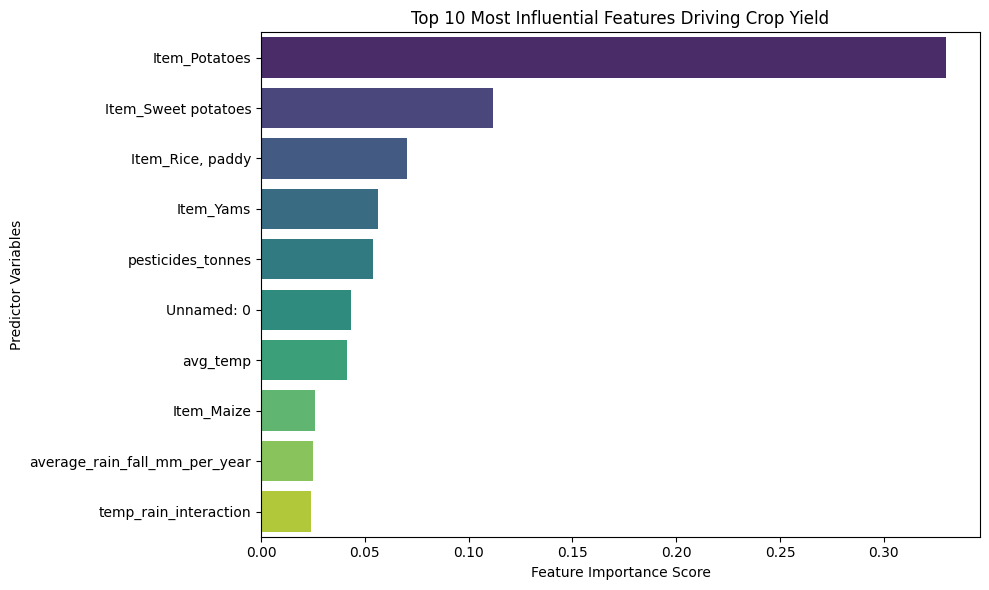

Top 10 Feature Importances:
                      feature  importance
                Item_Potatoes    0.329875
          Item_Sweet potatoes    0.111922
             Item_Rice, paddy    0.070238
                    Item_Yams    0.056438
            pesticides_tonnes    0.054067
                   Unnamed: 0    0.043249
                     avg_temp    0.041582
                   Item_Maize    0.025822
average_rain_fall_mm_per_year    0.025199
        temp_rain_interaction    0.024045


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# extracting feature importances from the trained random forest baseline model
importances = rf_baseline.feature_importances_
feature_names = X_train_scaled.columns

# creating a dataframe to pair feature names with their importance scores
# these scores showing the effect of that feature in the predictive equation
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

# selecting the top 10 most influential features
top_10 = importance_df.head(10)

# plotting a horizontal bar chart visualizing the top 10 features
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=top_10, palette='viridis')
plt.title('Top 10 Most Influential Features Driving Crop Yield')
plt.xlabel('Feature Importance Score')
plt.ylabel('Predictor Variables')
plt.tight_layout()
plt.show()

# printing the objective agronomic interpretation using print statements
print("Top 10 Feature Importances:")
print(top_10.to_string(index=False))

In [ ]:
# Potatoes naturally yield a much higher weight per hectare ($hg/ha$) compared
# to many other crops (like wheat, maize, or rice). Because of this huge numerical difference,
# the model relies heavily on the Item_Potatoes flag to instantly know what baseline number to
# start with before adjusting for weather.

# Climate still matters deeply, but its effect works on top of that baseline. Temperature and
# rainfall dictate whether a specific potato harvest will be above or below its normal average.